# Part 4: Multiple Regression {-}

In [1]:
import warnings
warnings.filterwarnings(action='ignore')

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In this part, we will extend from the simple linear regression
model to **multiple regression**.

These models
comprise the familiar linear models that take the form
\begin{equation*}
   Y = \beta_0 + \sum_{j=1}^p \beta_j x_j + \epsilon
\end{equation*}

where $\epsilon$ are assumed to be uncorrelated
with mean zero and variance $\sigma^2$.

Assuming that
the $\epsilon$ are normally distributed brings additional
nice theoretical properties, but is generally not essential.

We will go through the fundamental steps of fitting such a model
via an example.

\newpage

## Example: Factor Models {-}

References to the "beta" for a stock derive from the
slope of the regression line fit to a scatter plot where
excess return for that equity is the response, and excess market
return is the predictor.
Models of this form are an important component
of **Capital Asset Pricing Model (CAPM)**.

This idea is generalized to a **Factor Model**, which is any
linear model for excess return on an equity. The predictors
in the model are the **factors**, and can include any number
of macroeconomic or market fundamentals thought to influence
returns. Ideally, after accounting for the included factors,
the irreducible error should represent influences on return
specific to that stock.

The CAPM only includes the factor for excess market return.

The **Fama-French Three Factor Model** adds two
factors:

1. **Small Minus Big (SMB)**, the difference in returns between portfolios of small and large stocks.

2. **High Minus Low (HML)**, the difference in returns between portfolios of high and low book-to-market stocks.

**Exercise:** Explain why this is a mean model.

\answerlines{3}

\newpage

Kenneth French maintains a web site with data on the three factors

[http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html](http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)

This Python function uses `pandas-datareader` for easy access to the
daily factor data.

In [2]:
def getFamaFrench(from_date, to_date):
    
    import pandas_datareader.data as web    
    from datetime import datetime
    
    df = web.DataReader("F-F_Research_Data_Factors_daily", "famafrench")[0]
    
    df.columns=['MktRF','SMB','HML','RF']

    return df[(df.index >= from_date) & (df.index <= to_date)]

\newpage

An example, and the first few rows of the data returned are as follows. (These 
factors are periodically revised, and hence the exact
numbers may be different at the present time. This could affect the
subsequent analyses, as well.)

In [3]:
ffhold = getFamaFrench(from_date="2024-1-1", to_date="2024-6-30")
ffhold.head()

,MktRF,SMB,HML,RF
Date,,,,
2024-01-02,-0.70,-0.55,0.78,0.02
2024-01-03,-1.01,-1.94,-0.11,0.02
2024-01-04,-0.33,0.21,0.09,0.02
2024-01-05,0.15,-0.81,0.63,0.02
2024-01-08,1.49,0.90,-1.27,0.02


Let's get the data for PNC for the same time period.

In [4]:
PNCohlc = yf.Ticker("PNC").history(start="2024-01-01", end="2024-06-30")
PNCret = PNCohlc['Close'].pct_change().dropna()

Now find the excess returns for PNC. Note that the Fama-French
data file includes the risk free rate, with name `RF`.

We need to remove the first row of `ffhold` to make the dates line up. Also, the Fama-French data represents factors as percents, so we need to multiply our return by 100.

In [5]:
ffhold = ffhold[1:]
ffhold['PNCexret'] = 100*np.array(PNCret) - ffhold['RF']

\newpage

The three factor (mean) model we fit is
\begin{equation*}
   E(\mbox{PNC.Ex.Ret.}) = \beta_0 + \beta_1 \:\mbox{Mkt.Ex.Ret.}
   + \beta_2 \:\mbox{SMB} + \beta_3 \:\mbox{HML}
\end{equation*}

A Python command for fitting a least squares regression is `ols` in package `statsmodels`.

In [6]:
import statsmodels.api as sm

ff3modPNC = sm.OLS.from_formula(formula="PNCexret ~ MktRF + SMB + HML", data=ffhold).fit()

To see the parameter estimates and their standard errors for the estimators:

In [7]:
ff3modPNC.params

Intercept    0.029424
MktRF        0.861896
SMB          0.182062
HML          1.510769
dtype: float64

In [8]:
ff3modPNC.bse

Intercept    0.091439
MktRF        0.138699
SMB          0.131220
HML          0.150929
dtype: float64

You can obtain the residuals from `ff3modPNC.resid` and the fitted values from `ff3modPNC.fittedvalues`.

Inspect `ff3modPNC.summary()` for a more complete summary.

\newpage

## Diagnostic Plots {-}

The figure below shows four scatter plots constructed by
Francis Anscombe in 1973, and referred to as
**Anscombe's Quartet**.

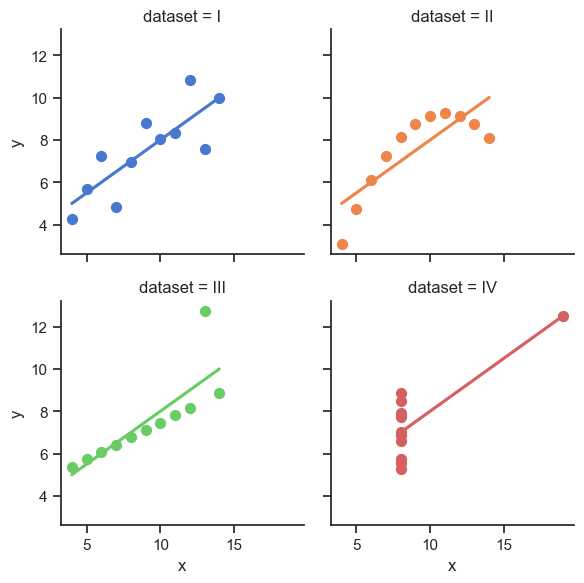

In [9]:
# The code is adapted from https://seaborn.pydata.org/examples/anscombes_quartet.html

import seaborn as sns
sns.set(style="ticks")

ansdf = sns.load_dataset("anscombe")

hold = sns.lmplot(x="x", y="y", col="dataset", 
        hue="dataset", data=ansdf, col_wrap=2,
        ci=None, palette="muted", height=3,
        scatter_kws={"s": 50, "alpha": 1})

\newpage

The interesting feature of these four data sets is that the summary statistics are equal across them all:
The sample mean and variance of $x$ and $y$, and the correlation between $x$ and $y$ match in each of the
four cases. This implies that the equation for the least squares regression line is the same across these.

**Exercise:** This can be taken a step further: We could find that the residual sum of squares in all four cases is exactly the same. What does this imply about the inference for $\beta_1$ in all four cases? What is the message we take away from this example?

\answerlines{12}

\newpage

A useful diagnostic plot is that of the **residuals versus
the fitted values**. There are a wide range of models for which this
is an invaluable tool.

**Exercise:** If the assumptions of the model are correct,
what should we see in the plot of residuals versus fitted values?

\answerlines{7}

**Exercise:** Use the code below to explore the plot of residuals versus fitted values in the case of Anscombe's Quartet. Comment on the results.

\answerlines{10}

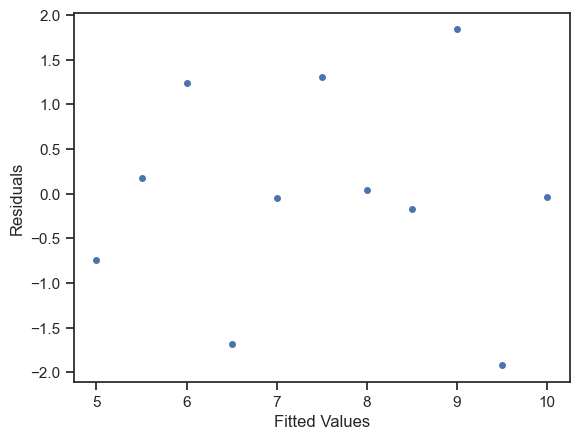

In [10]:
ansgrp = ansdf.groupby(ansdf.dataset)
onegrp = ansgrp.get_group("I")

ansfit = sm.OLS.from_formula(formula="y~x", data=onegrp).fit()

plt.scatter(ansfit.fittedvalues, ansfit.resid, s=16)
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

\newpage

**Exercise:** Your colleague says, "I found the correlation
between the residuals and fitted values to be equal to zero, so there is 
clearly no relationship between the residuals and fitted values. 
So, the model must be fine." Do you agree with this logic?

\answerlines{10}

The residuals are also often plotted against each of the predictors. Our assumption is that the irreducible error is "random scatter" around the regression line/plane. If this assumption is true, there should be no remaining pattern evident in these plots.

\newpage

### Assessing Normality of Irreducible Errors {-}

We have already mentioned that when the irreducible errors can be assumed to be iid normal, then there are additional appealing results that can be stated:

1. The least squares estimator can be justified as being the maximum likelihood estimators.

2. The least squares estimators are exactly normal.

3. The least squares estimators, when appropriately scaled, have a $t$-distribution, which can be used to construct exact confidence intervals and hypothesis tests.

4. The least squares approach is best suited to cases where the scatter around the mean model is symmetric around zero, and free from extreme values.

For the above reasons, it can be useful to assess the normality of the residuals, as a means of assessing the normality of the irreducible error. 

**Comment:** It is good to keep in mind, however, that there are versions of the central limit theorem that state that, assuming the errors are independent (and under some regularity conditions), the least squares estimator will be approximately normal for large $n$.

\newpage

The standard tool for assessing normality is the **normal probability plot**.

This plot compares the sorted observations (order statistics) with the expected value of these order statistics under the (standard) normal distribution. If the points fall systematically off a straight line, it shows deficiencies in the normal assumption.

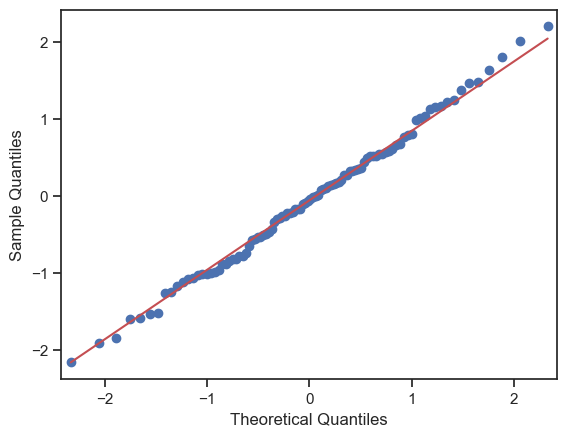

In [11]:
from statsmodels.graphics.gofplots import qqplot
from scipy.stats import norm

qqplot(norm.rvs(size=100),line="s")
plt.show()

\newpage

**Exercise:** Explain how the normal probability plot would appear if the sample was drawn from a distribution which has tails heavier than that of the normal. What if the tails were lighter than the normal? Why is the comparison made with the standard normal distribution?

\answerlines{20}

\newpage

Let's now return to our PNC example.
The figure below shows three diagnostic plots:

1. Plot of residuals versus fitted values.
2. Plot of residuals versus the predictors.
3. Normal probability plot of the residuals.

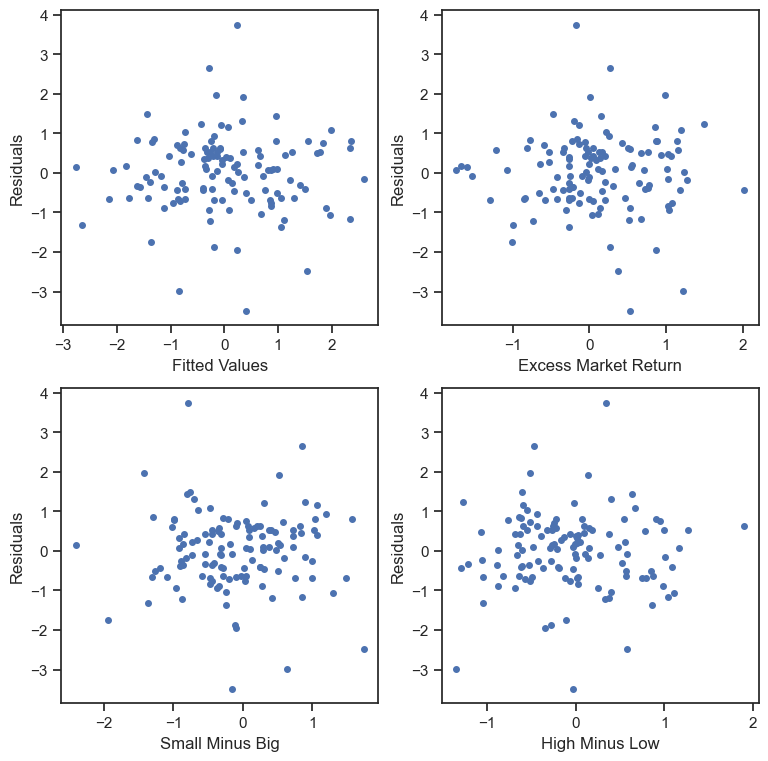

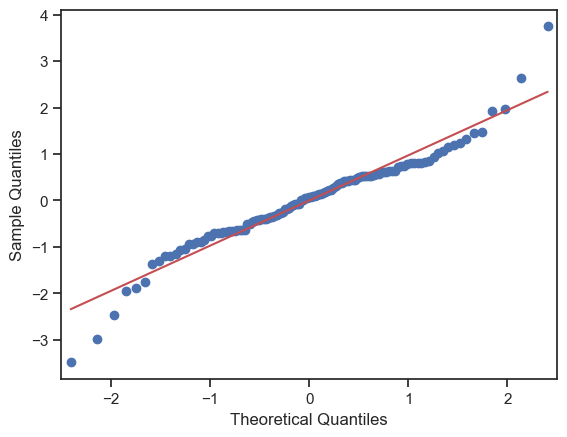

In [12]:
from statsmodels.graphics.gofplots import qqplot
import scipy.stats.distributions as spdists

fig, axs = plt.subplots(2, 2,figsize=[9,9])

axs[0,0].scatter(ff3modPNC.fittedvalues, ff3modPNC.resid, s=16)
axs[0,0].set(xlabel="Fitted Values",ylabel="Residuals")

axs[0,1].scatter(ffhold.MktRF, ff3modPNC.resid, s=16)
axs[0,1].set(xlabel="Excess Market Return",ylabel="Residuals")

axs[1,0].scatter(ffhold.SMB, ff3modPNC.resid, s=16)
axs[1,0].set(xlabel="Small Minus Big",ylabel="Residuals")

axs[1,1].scatter(ffhold.HML, ff3modPNC.resid, s=16)
axs[1,1].set(xlabel="High Minus Low",ylabel="Residuals")

plt.show()

qqplot(ff3modPNC.resid, line='s')
plt.show()

**Exercise:** Comment on the quality of the fit.

\answerlines{9}

\newpage

## Linear Regression in Matrix Notation {-}

First, recall our simple linear regression model:
\begin{equation*}
   Y_i = \beta_0 + \beta_1 X_i + \epsilon_i, \:\:\:i=1,2,\ldots,n
\end{equation*}

We can rewrite this model in matrix notation by letting
\begin{equation*}
%\begin{array}{cc} 
{\bf Y} = \left[\begin{array}{c}Y_1\\Y_2\\ \vdots \\Y_n\end{array}\right]
\:\:\:\:\:\:
{\bf X} = \left[\begin{array}{cc}1&X_1\\1&X_2\\ \vdots & \vdots 
   \\1&X_n\end{array}\right] 
\:\:\:\:\:\:
\boldsymbol{\beta} = \left[\begin{array}{c}\beta_0\\\beta_1\end{array}\right]
\:\:\:\:\:\:
\boldsymbol{\epsilon} = \left[\begin{array}{c}\epsilon_1\\\epsilon_2\\ \vdots \\\epsilon_n\end{array}\right]
%\end{array}
\end{equation*}
and then noting that
\begin{equation*}
   {\bf Y} = {\bf X} \boldsymbol{\beta} + \boldsymbol{\epsilon}
\end{equation*}

When moving to multiple regression, the main change we must make is to add
columns to the matrix ${\bf X}$, commonly called the **design matrix**,
and add entries to $\boldsymbol{\beta}$:
\begin{equation*}
{\bf X} = \left[\begin{array}{ccccc}
1 & X_{11} & X_{12} & \cdots & X_{1,p}\\
1 & X_{21} & X_{22} & \cdots & X_{2,p}\\
\vdots & \vdots & \vdots & & \vdots \\
1 & X_{n1} & X_{n2} & \cdots & X_{n,p}\\
\end{array}\right] 
\:\:\:\:\:\:
\boldsymbol{\beta} = \left[\begin{array}{c}\beta_0\\\beta_1\\ \vdots\\ \beta_{p}\end{array}\right]
\end{equation*}

\newpage

One can show that the least
squares estimators (now a vector) are
\begin{equation*}
   \boldsymbol{\widehat \beta} = ({\bf X}^T{\bf X})^{-1} {\bf X}^T{\bf Y}.
\end{equation*}
and can now define the vector of fitted values and residuals
as
\begin{equation*}
{\bf \widehat {\bf Y}} = \left[\begin{array}{c}\widehat Y_1\\\widehat Y_2\\ \vdots \\\widehat Y_n\end{array}\right]
\:\:\:\:\:\mbox{and}\:\:\:\:\:
\boldsymbol{\widehat \epsilon} = \left[\begin{array}{c}\widehat \epsilon_1\\\widehat \epsilon_2\\ \vdots \\\widehat \epsilon_n\end{array}\right]
\end{equation*}
and it follows that 
\begin{equation*}
   \widehat {\bf Y} = {\bf X} \boldsymbol{\widehat \beta} \:\:\:\:\mbox{and}\:\:\: \boldsymbol{\widehat \epsilon}= {\bf Y} - {\bf \widehat Y}.
\end{equation*}

\newpage

## The Hat Matrix {-}

We note that we could write
\begin{equation*}
   \widehat {\bf Y} = {\bf X} \boldsymbol{\widehat \beta} = {\bf X} ({\bf X}^T{\bf X})^{-1} {\bf X}^T{\bf Y} = {\bf H} {\bf Y}
\end{equation*}
where
\begin{equation*}
   {\bf H} = {\bf X} ({\bf X}^T{\bf X})^{-1} {\bf X}^T
\end{equation*}
is called the **hat matrix** (because it puts a "hat" on ${\bf Y}$).

The diagonal entries of ${\bf H}$ are referred to as the **leverages**.

**Comment:** 
Mathematically, ${\bf H}$ is a **projection matrix**, as it "projects" the vector of observed
responses ${\bf Y}$ onto the space of all vectors which are linear combinations of the columns
of ${\bf X}$. In fact, we note that ${\bf H}$ is symmetric and **idempotent**, meaning that ${\bf H} {\bf H} = {\bf H}$.

**Exercise:** Show that ${\bf I} - {\bf H}$ is also symmetric and idempotent.

\answerlines{5}

\newpage
## Additional Results {-}

A range of important results can be proven:

1. The least squares estimator for $\boldsymbol{\beta}$ is $\boldsymbol{\widehat \beta} = ({\bf X}^T{\bf X})^{-1} {\bf X}^T {\bf Y}$.
2. The variance of $\boldsymbol{\widehat \beta}$ is $\sigma^2({\bf X}^T{\bf X})^{-1}$.
3. $\widehat {\bf Y} = {\bf X} \boldsymbol{\widehat \beta} = {\bf H} {\bf Y}$, where the (symmetric, idempotent) hat matrix ${\bf H}$ is defined as above.
4. $\boldsymbol{\widehat \epsilon} = {\bf Y} - {\bf \widehat Y} = ({\bf I} - {\bf H}) {\bf Y}$.
5. If $\boldsymbol{\epsilon}$ is assumed normal with mean zero and variance $\sigma^2\,{\bf I}$, the following hold:
    - $\boldsymbol{\widehat \beta}$ is the maximum likelihood estimator.
    - ${\bf Y}$ is multivariate normal with mean ${\bf X} \boldsymbol{\beta}$ and covariance $\sigma^2\,{\bf I}$.
    - $\boldsymbol{\widehat \beta}$ is multivariate normal with mean $\boldsymbol{\beta}$ and covariance $\sigma^2({\bf X}^T{\bf X})^{-1}$.
    - ${\bf \widehat Y}$ is multivariate normal with mean ${\bf X} \boldsymbol{\beta}$ and covariance $\sigma^2\,{\bf H}$.
    - $\boldsymbol{\widehat \epsilon}$ is multivariate normal with mean zero and covar. $\sigma^2({\bf I} - {\bf H})$.

\newpage

## Degrees of Freedom {-}

One key thing that does change when moving to multiple regression is the number of
**degrees of freedom** in the residual vector.

Recall that we had seen previously that with simple linear regression, it held that
\begin{equation*}
   \sum_i \widehat \epsilon_i = 0 \:\:\:\mbox{and}\:\:\: \sum_i \widehat \epsilon_i X_i = 0.
\end{equation*}
This result is one way of seeing why the residuals only have $n-2$ degrees of freedom in the
case of simple linear regression: There are two constraints placed on the vector of residuals.

But, these facts could be written more compactly using matrix notation: ${\bf X}^T \boldsymbol{\widehat \epsilon} = {\bf 0}$,
where ${\bf 0}$ is a vector consisting entirely of zeros.

In fact, this result extends to multiple regression: The vector of residuals $\boldsymbol{\widehat \epsilon}$ is
orthogonal to **every column** of ${\bf X}$, i.e., ${\bf X}^T \boldsymbol{\widehat \epsilon} = {\bf 0}$.

\newpage

**We now can state that there are $n-(p+1)$ degrees of freedom in the residuals**, and hence need to
update some of our previous results. (Note that simple linear regression corresponds to
the case where $p=1$.) 

In particular:

1. The unbiased estimator of $\sigma^2$ is
\begin{equation*}
   \widehat \sigma^2 = {\rm RSS}\bigg/(n-p-1)
\end{equation*}
2. When the errors of iid normal, the statistic
\begin{equation*}
   \frac{\widehat \beta_i - \beta_i}{\widehat {\rm SE}(\widehat \beta_i)}
\end{equation*}
has the $t$-distribution with $n-p-1$ degrees of freedom. Hence, a 100$(1-\alpha)\%$ confidence interval for $\beta_i$ is formed as
\begin{equation*}
   \widehat \beta_i \pm t_{\alpha/2, n-p-1} \,\widehat {\rm SE}(\widehat \beta_i)
\end{equation*}
and hypothesis tests concerning $\beta_i$ should compare the test statistic
(the "t value") with the $t$-distribution with $n-p-1$ degrees of freedom.
3. For large $n$, and assuming the errors are independent, we can appeal to the central limit theorem and construct an approximate 100$(1-\alpha)\%$ confidence interval for $\beta_i$ using
\begin{equation*}
   \widehat \beta_i \pm z_{\alpha/2} \,\widehat {\rm SE}(\widehat \beta_i)
\end{equation*}